In [4]:
# %% [1] Setup & Dependencies
!mkdir -p data && wget -q -nc "https://huggingface.co/datasets/rony000013/indiccorpV2-5k/resolve/main/data.parquet" -O "data/data.parquet"
!git clone -q https://github.com/syedsarfarazakhtar/Word-Similarity-Datasets-for-Indian-Languages.git data/Word-Similarity-Datasets-for-Indian-Languages || true

In [1]:
# %% [2] Imports, Configuration & Reproducibility
import json
import random
import re
import unicodedata
# import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
# from reportlab.lib import colors
# from reportlab.lib.pagesizes import A4
# from reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet
# from reportlab.lib.units import inch
# from reportlab.platypus import Image, Paragraph, SimpleDocTemplate, Spacer, Table, TableStyle
from scipy.stats import rankdata, spearmanr
from sklearn.manifold import TSNE
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT_DIR = Path(".")
DATA_DIR = PROJECT_DIR / "data"
BENCHMARK_DIR = DATA_DIR / "Word-Similarity-Datasets-for-Indian-Languages"
MODEL_DIR = PROJECT_DIR / "models"
EMBEDDING_DIR = PROJECT_DIR / "embeddings"
RESULT_DIR = PROJECT_DIR / "results"
REPORT_DIR = PROJECT_DIR / "report"

for d in [MODEL_DIR, EMBEDDING_DIR, RESULT_DIR, REPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

LANGUAGES = ["Gujarati", "Hindi", "Marathi", "Punjabi", "Tamil", "Telugu", "Urdu"]
EMBEDDING_DIM = 300
MIN_COUNT = 2
WINDOW_SIZE = 5
NEGATIVE_SAMPLES = 5
BATCH_SIZE = 2048 * 4
LEARNING_RATE = 0.003
EPOCHS = 150

c:\Users\boraw\Downloads\nlp_assignment_submission\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# %% [3] Load & Preprocess IndicCorpV2 Corpus
corpus_df = pd.read_parquet(DATA_DIR / "data.parquet")
corpus_df = corpus_df[corpus_df["language"].isin(LANGUAGES)].copy()
print("Filtered corpus shape:", corpus_df.shape)
print(corpus_df["language"].value_counts())


def preprocess_text(text: str) -> list[str]:
    if not isinstance(text, str):
        return []
    text = unicodedata.normalize("NFC", text).lower()
    tokens = re.findall(r"\w+", text, flags=re.UNICODE)
    return [w for w in tokens if len(w) > 1 and not w.isdigit()]


def get_character_ngrams(word: str, min_n: int = 3, max_n: int = 6) -> list[str]:
    wrapped = f"<{word}>"
    return list({
        wrapped[i : i + n]
        for n in range(min_n, max_n + 1)
        for i in range(len(wrapped) - n + 1)
    })


language_data = {}

for lang in sorted(corpus_df["language"].unique()):
    texts = corpus_df.loc[corpus_df["language"] == lang, "text"]
    sentences = [toks for t in tqdm(texts, desc=f"Preprocessing {lang}") if len(toks := preprocess_text(t)) >= 2]

    word_counts = Counter(w for s in sentences for w in s)
    vocab = {w: c for w, c in word_counts.items() if c >= MIN_COUNT}
    word_to_id = {w: idx for idx, w in enumerate(vocab)}

    encoded_sentences = [
        enc for s in sentences
        if len(enc := [word_to_id[w] for w in s if w in word_to_id]) >= 2
    ]

    ngram_to_id = {}
    word_id_to_ngrams = [None] * len(word_to_id)
    for word, idx in word_to_id.items():
        ids = []
        for ng in get_character_ngrams(word):
            if ng not in ngram_to_id:
                ngram_to_id[ng] = len(ngram_to_id)
            ids.append(ngram_to_id[ng])
        word_id_to_ngrams[idx] = ids

    language_data[lang] = {
        "word_counts": word_counts,
        "word_to_id": word_to_id,
        "encoded_sentences": encoded_sentences,
        "ngram_to_id": ngram_to_id,
        "word_id_to_ngrams": word_id_to_ngrams,
    }
    print(f"{lang}: {len(encoded_sentences)} sentences | Vocab: {len(word_to_id)} | N-grams: {len(ngram_to_id)}")

Filtered corpus shape: (35000, 3)
language
Gujarati    5000
Hindi       5000
Marathi     5000
Punjabi     5000
Tamil       5000
Telugu      5000
Urdu        5000
Name: count, dtype: int64


Preprocessing Gujarati: 100%|██████████| 5000/5000 [00:00<00:00, 6861.58it/s]


Gujarati: 4821 sentences | Vocab: 3128 | N-grams: 13898


Preprocessing Hindi: 100%|██████████| 5000/5000 [00:01<00:00, 4323.77it/s]


Hindi: 4888 sentences | Vocab: 2526 | N-grams: 12451


Preprocessing Marathi: 100%|██████████| 5000/5000 [00:00<00:00, 6652.36it/s]


... (5 outputs left out)

Preprocessing Telugu: 100%|██████████| 5000/5000 [00:00<00:00, 8202.22it/s]


Telugu: 4559 sentences | Vocab: 2290 | N-grams: 10205


Preprocessing Urdu: 100%|██████████| 5000/5000 [00:00<00:00, 8012.61it/s]


Urdu: 4842 sentences | Vocab: 13564 | N-grams: 87398


In [7]:
# %% [4] FastText Skip-Gram with Negative Sampling
def generate_training_pairs(encoded_sentences: list[list[int]], window_size: int = 5) -> torch.Tensor:
    pairs = []
    for sentence in encoded_sentences:
        n = len(sentence)
        for i, target in enumerate(sentence):
            for j in range(max(0, i - window_size), min(n, i + window_size + 1)):
                if i != j:
                    pairs.append((target, sentence[j]))
    return torch.tensor(pairs, dtype=torch.long)


def create_negative_distribution(word_counts: Counter, word_to_id: dict) -> torch.Tensor:
    counts = np.array([word_counts[w] for w in word_to_id], dtype=np.float64)
    probs = counts ** 0.75
    probs /= probs.sum()
    return torch.tensor(probs, dtype=torch.float32, device=device)


def train_fasttext(
    pair_tensor: torch.Tensor,
    negative_distribution: torch.Tensor,
    vocab_size: int,
    word_id_to_ngrams: list[list[int]],
    ngram_vocab_size: int,
    epochs: int = EPOCHS,
):
    input_emb = nn.EmbeddingBag(ngram_vocab_size, EMBEDDING_DIM, mode="mean").to(device)
    output_emb = nn.Embedding(vocab_size, EMBEDDING_DIM).to(device)

    nn.init.uniform_(input_emb.weight, -0.5 / EMBEDDING_DIM, 0.5 / EMBEDDING_DIM)
    nn.init.zeros_(output_emb.weight)

    optimizer = torch.optim.Adam(
        list(input_emb.parameters()) + list(output_emb.parameters()),
        lr=LEARNING_RATE,
    )

    total_pairs = len(pair_tensor)
    for epoch in range(epochs):
        perm = torch.randperm(total_pairs)
        total_loss = 0.0
        num_batches = 0

        for start in range(0, total_pairs, BATCH_SIZE):
            batch = pair_tensor[perm[start : start + BATCH_SIZE]]
            targets = batch[:, 0]
            contexts = batch[:, 1].to(device)

            negatives = torch.multinomial(
                negative_distribution,
                targets.shape[0] * NEGATIVE_SAMPLES,
                replacement=True,
            ).reshape(targets.shape[0], NEGATIVE_SAMPLES)

            flat_ids, offsets = [], []
            for idx in targets.tolist():
                offsets.append(len(flat_ids))
                flat_ids.extend(word_id_to_ngrams[idx])

            target_vecs = input_emb(
                torch.tensor(flat_ids, dtype=torch.long, device=device),
                torch.tensor(offsets, dtype=torch.long, device=device),
            )

            pos_vecs = output_emb(contexts)
            pos_loss = torch.nn.functional.logsigmoid(torch.sum(target_vecs * pos_vecs, dim=1))

            neg_vecs = output_emb(negatives)
            neg_scores = torch.bmm(neg_vecs, target_vecs.unsqueeze(2)).squeeze(2)
            neg_loss = torch.nn.functional.logsigmoid(-neg_scores).sum(dim=1)

            loss = -(pos_loss + neg_loss).mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            num_batches += 1

        if (epoch + 1) % 25 == 0 or epoch == 0 or (epoch + 1) == epochs:
            print(f"  Epoch {epoch + 1}/{epochs} | Loss: {total_loss / max(1, num_batches):.4f}")

    return input_emb, output_emb

In [8]:
# %% [5] Train FastText Models & Save Checkpoints + Vocabulary Mappings
fasttext_models = {}

for lang, data in language_data.items():
    print(f"\n=== Training FastText for {lang} ===")
    pairs = generate_training_pairs(data["encoded_sentences"], WINDOW_SIZE)
    neg_dist = create_negative_distribution(data["word_counts"], data["word_to_id"])
    print(f"Training pairs: {len(pairs)}")

    ft_in, ft_out = train_fasttext(
        pair_tensor=pairs,
        negative_distribution=neg_dist,
        vocab_size=len(data["word_to_id"]),
        word_id_to_ngrams=data["word_id_to_ngrams"],
        ngram_vocab_size=len(data["ngram_to_id"]),
        epochs=EPOCHS,
    )

    with torch.no_grad():
        vocab_vecs = np.stack([
            ft_in.weight[torch.tensor(ng_ids, dtype=torch.long, device=device)].mean(dim=0).cpu().numpy()
            for ng_ids in data["word_id_to_ngrams"]
        ]).astype(np.float32)

    fasttext_models[lang] = {"input": ft_in, "output": ft_out, "vocab_vectors": vocab_vecs}

    # Save model checkpoint for private evaluation
    torch.save(
        {
            "input_embeddings": ft_in.state_dict(),
            "output_embeddings": ft_out.state_dict(),
            "ngram_to_id": data["ngram_to_id"],
            "word_to_id": data["word_to_id"],
            "embedding_dim": EMBEDDING_DIM,
        },
        MODEL_DIR / f"{lang.lower()}_fasttext.pt",
    )

    # Save vocabulary mapping (JSON word->id + (V, 300) vectors)
    with open(EMBEDDING_DIR / f"{lang.lower()}_vocabulary.json", "w", encoding="utf-8") as f:
        json.dump(data["word_to_id"], f, ensure_ascii=False, indent=2)
    np.save(EMBEDDING_DIR / f"{lang.lower()}_fasttext_vocabulary_vectors.npy", vocab_vecs)


=== Training FastText for Gujarati ===
Training pairs: 1221194
  Epoch 1/150 | Loss: 2.8004
  Epoch 25/150 | Loss: 2.2089
  Epoch 50/150 | Loss: 2.1740
  Epoch 75/150 | Loss: 2.1659
  Epoch 100/150 | Loss: 2.1618
  Epoch 125/150 | Loss: 2.1598
  Epoch 150/150 | Loss: 2.1590

=== Training FastText for Hindi ===
Training pairs: 1236690
  Epoch 1/150 | Loss: 2.8037
  Epoch 25/150 | Loss: 2.2788
  Epoch 50/150 | Loss: 2.2519
  Epoch 75/150 | Loss: 2.2456
  Epoch 100/150 | Loss: 2.2432
  Epoch 125/150 | Loss: 2.2418
  Epoch 150/150 | Loss: 2.2410

=== Training FastText for Marathi ===
Training pairs: 1270618
  Epoch 1/150 | Loss: 2.7926
  Epoch 25/150 | Loss: 2.2094
  Epoch 50/150 | Loss: 2.1768
  Epoch 75/150 | Loss: 2.1680
  Epoch 100/150 | Loss: 2.1645
  Epoch 125/150 | Loss: 2.1626
  Epoch 150/150 | Loss: 2.1613

=== Training FastText for Punjabi ===
Training pairs: 1181796
  Epoch 1/150 | Loss: 2.8085
  Epoch 25/150 | Loss: 2.2379
  Epoch 50/150 | Loss: 2.2064
  Epoch 75/150 | Loss: 2

In [9]:
# %% [6] Checkpoint Loading & Arbitrary/OOV Word Embedding Inference
def load_model_checkpoint(language: str) -> dict:
    ckpt_path = MODEL_DIR / f"{language.lower()}_fasttext.pt"
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    ngram_to_id = ckpt["ngram_to_id"]
    emb = nn.EmbeddingBag(len(ngram_to_id), ckpt["embedding_dim"], mode="mean").to(device)
    emb.load_state_dict(ckpt["input_embeddings"])
    emb.eval()
    return {"input": emb, "ngram_to_id": ngram_to_id, "word_to_id": ckpt["word_to_id"]}


def generate_embedding(word: str, language: str, loaded_state: dict | None = None) -> np.ndarray:
    word = unicodedata.normalize("NFC", word.lower())
    if loaded_state is not None:
        input_emb, ngram_to_id = loaded_state["input"], loaded_state["ngram_to_id"]
    else:
        input_emb = fasttext_models[language]["input"]
        ngram_to_id = language_data[language]["ngram_to_id"]

    ng_ids = [ngram_to_id[ng] for ng in get_character_ngrams(word) if ng in ngram_to_id]
    if not ng_ids:
        return np.zeros(EMBEDDING_DIM, dtype=np.float32)

    with torch.no_grad():
        ids_t = torch.tensor(ng_ids, dtype=torch.long, device=device)
        return input_emb.weight[ids_t].mean(dim=0).cpu().numpy().astype(np.float32)

In [12]:
# %% [7] Intrinsic Evaluation on Public Word Similarity Benchmarks
benchmark_files = list(BENCHMARK_DIR.rglob("*.txt"))
language_files = {
    lang: f
    for f in benchmark_files
    for lang in LANGUAGES
    if lang.lower() in f.stem.lower()
}

def parse_benchmark_line(line: str):
    line = line.strip()
    if not line:
        return None
    if "\t" in line:
        parts = [p.strip() for p in line.split("\t") if p.strip()]
    elif "," in line:
        parts = [p.strip() for p in line.split(",") if p.strip()]
    elif ";" in line:
        parts = [p.strip() for p in line.split(";") if p.strip()]
    else:
        parts = line.split()

    if len(parts) < 3:
        return None

    # Find numeric score (check last column first, then any column >= 2)
    score = None
    for idx in [len(parts) - 1, *range(2, len(parts) - 1)]:
        try:
            score = float(parts[idx])
            break
        except ValueError:
            continue

    if score is None:
        return None

    return {
        "word1": unicodedata.normalize("NFC", parts[0].lower()),
        "word2": unicodedata.normalize("NFC", parts[1].lower()),
        "human_score": score,
    }

benchmark_data = {}
for lang, file in sorted(language_files.items()):
    rows = []
    with open(file, "r", encoding="utf-8", errors="replace") as f:
        raw_lines = f.readlines()
    for line in raw_lines:
        parsed = parse_benchmark_line(line)
        if parsed is not None:
            rows.append(parsed)

    df_lang = pd.DataFrame(rows, columns=["word1", "word2", "human_score"])
    print(f"Loaded {lang}: {len(df_lang)} word pairs")
    if df_lang.empty:
        print(f"  -> Skipping {lang} (no valid scored pairs). Sample lines: {raw_lines[:3]}")
        continue
    benchmark_data[lang] = df_lang


def cosine_similarity(v1: np.ndarray, v2: np.ndarray) -> float:
    n1, n2 = np.linalg.norm(v1), np.linalg.norm(v2)
    return 0.0 if (n1 == 0 or n2 == 0) else float(np.dot(v1, v2) / (n1 * n2))


evaluation_results = []
evaluation_predictions = {}
coverage_rows = []

for lang in LANGUAGES:
    if lang not in benchmark_data or lang not in language_data:
        continue
    df = benchmark_data[lang]
    vocab = language_data[lang]["word_to_id"]

    bench_vocab = set(df["word1"]) | set(df["word2"])
    covered = len(bench_vocab & vocab.keys())
    coverage_rows.append({
        "Language": lang,
        "Benchmark Vocabulary": len(bench_vocab),
        "Covered Words": covered,
        "OOV Words": len(bench_vocab) - covered,
        "Coverage (%)": 100.0 * covered / len(bench_vocab) if bench_vocab else 0.0,
    })

    pred_scores, pairs_emb = [], []
    oov_occurrences = 0
    for _, row in df.iterrows():
        w1, w2 = row["word1"], row["word2"]
        oov_occurrences += int(w1 not in vocab) + int(w2 not in vocab)
        v1 = generate_embedding(w1, lang)
        v2 = generate_embedding(w2, lang)
        pred_scores.append(cosine_similarity(v1, v2))
        pairs_emb.append(np.stack([v1, v2]))

    pairs_arr = np.array(pairs_emb, dtype=np.float32)
    assert pairs_arr.shape == (len(df), 2, EMBEDDING_DIM), f"Bad shape for {lang}"
    assert np.isfinite(pairs_arr).all(), f"Non-finite values in {lang}"

    np.save(EMBEDDING_DIR / f"{lang.lower()}_fasttext_pairs.npy", pairs_arr)
    corr, p_val = spearmanr(pred_scores, df["human_score"])

    evaluation_results.append({
        "Language": lang,
        "Spearman": corr,
        "P-value": p_val,
        "Total Pairs": len(df),
        "OOV Token Occurrences": oov_occurrences,
        "OOV Rate (%)": 100.0 * oov_occurrences / (2 * len(df)),
    })
    evaluation_predictions[lang] = pred_scores

results_df = pd.DataFrame(evaluation_results)
coverage_df = pd.DataFrame(coverage_rows)
macro_spearman = results_df["Spearman"].mean()

display(results_df)
print(f"Macro-average Spearman: {macro_spearman:.4f}")
display(coverage_df)

Loaded Gujarati: 163 word pairs
Loaded Hindi: 235 word pairs
Loaded Marathi: 104 word pairs
Loaded Punjabi: 143 word pairs
Loaded Tamil: 96 word pairs
Loaded Telugu: 111 word pairs
Loaded Urdu: 100 word pairs


,Language,Spearman,P-value,Total Pairs,OOV Token Occurrences,OOV Rate (%)
0,Gujarati,-0.013178,0.867403,163,312,95.705521
1,Hindi,-0.064492,0.324922,235,445,94.680851
2,Marathi,0.120665,0.222413,104,193,92.788462
3,Punjabi,-0.130962,0.118982,143,275,96.153846
4,Tamil,0.028446,0.783229,96,190,98.958333
5,Telugu,0.035390,0.712312,111,222,100.000000
6,Urdu,0.256063,0.010127,100,41,20.500000


Macro-average Spearman: 0.0331


,Language,Benchmark Vocabulary,Covered Words,OOV Words,Coverage (%)
0,Gujarati,221,7,214,3.167421
1,Hindi,318,13,305,4.088050
2,Marathi,135,7,128,5.185185
3,Punjabi,206,8,198,3.883495
4,Tamil,135,2,133,1.481481
5,Telugu,160,0,160,0.000000
6,Urdu,146,113,33,77.397260


In [13]:
!apt-get -qq update && apt-get -qq install -y fonts-noto-core

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-noto-mono.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../fonts-noto-mono_20201225-2_all.deb ...
Unpacking fonts-noto-mono (20201225-2) ...
Selecting previously unselected package fonts-noto-core.
Preparing to unpack .../fonts-noto-core_20201225-2_all.deb ...
Unpacking fonts-noto-core (20201225-2) ...
Setting up fonts-noto-mono (20201225-2) ...
Setting up fonts-noto-core (20201225-2) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


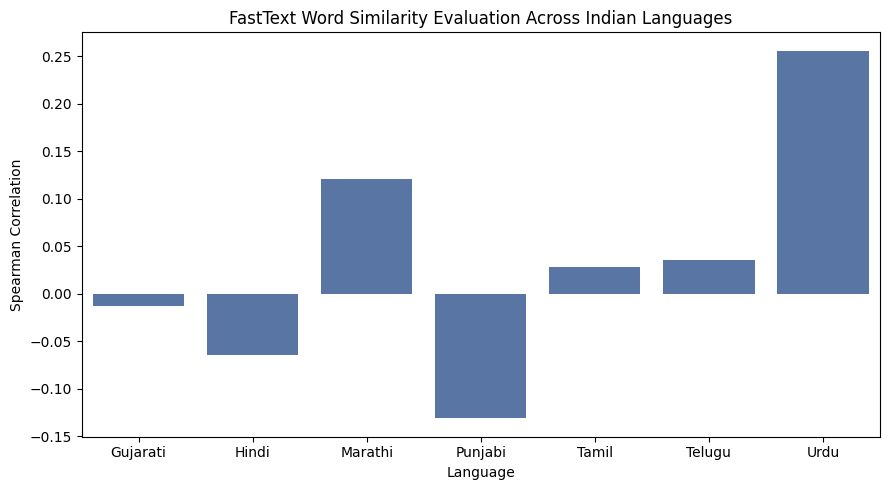

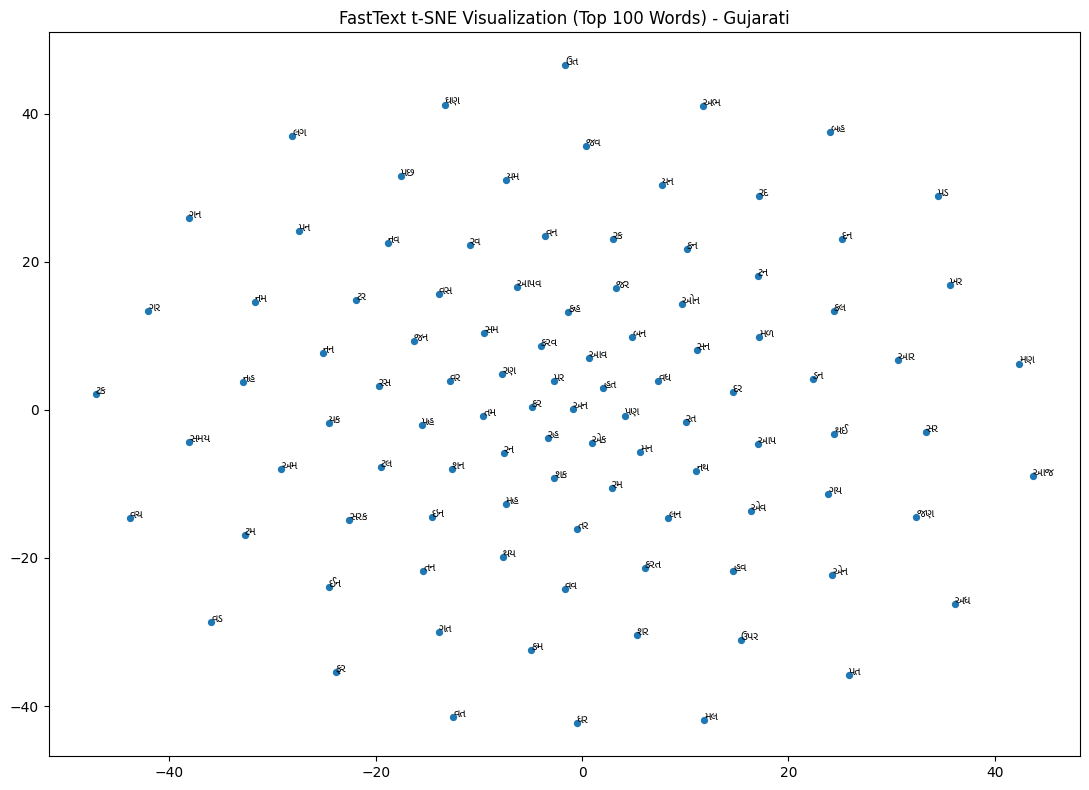

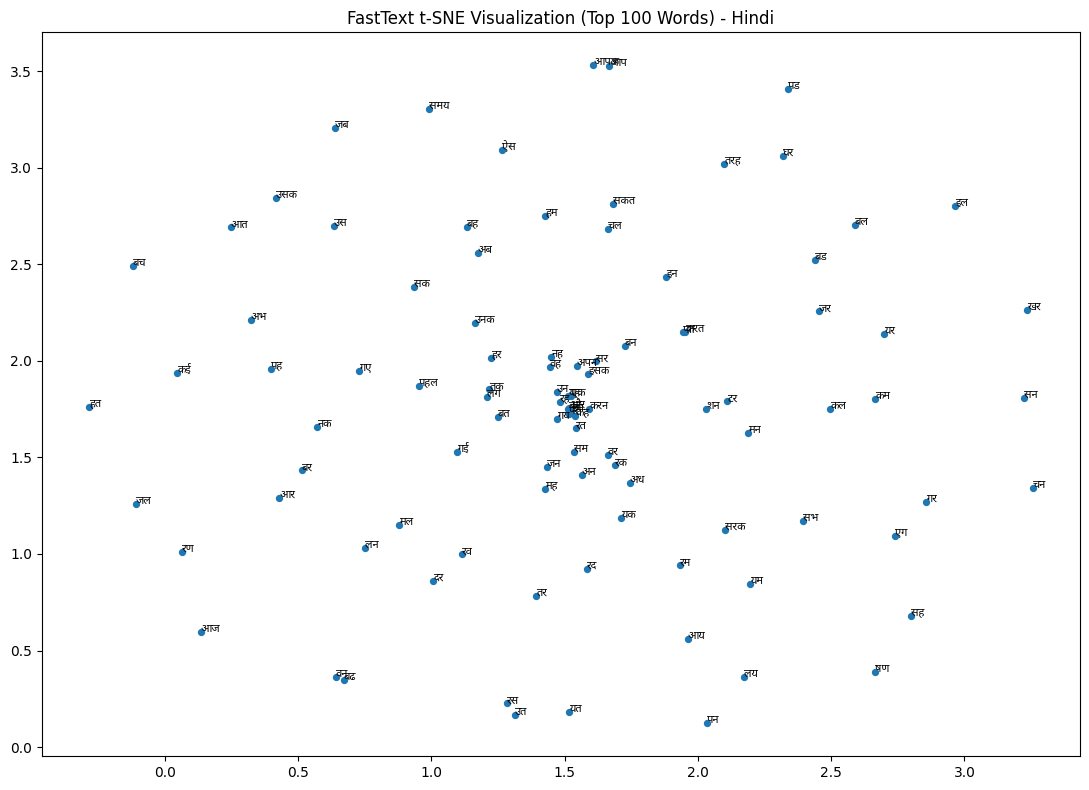

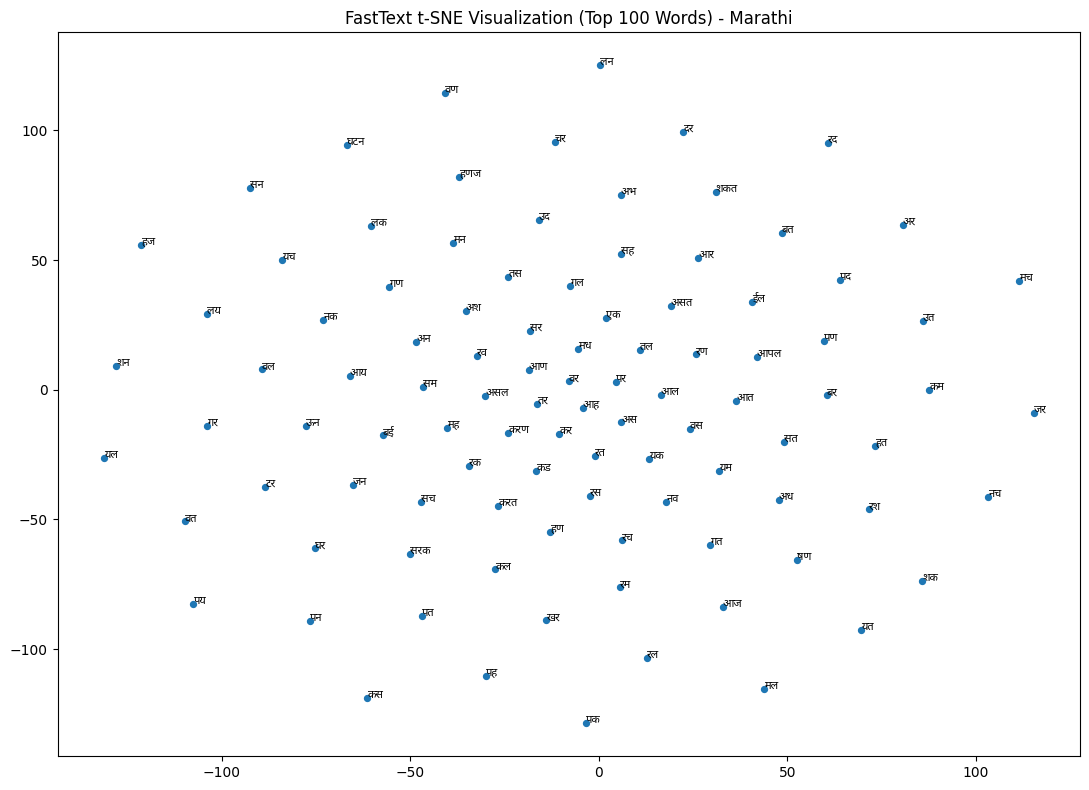

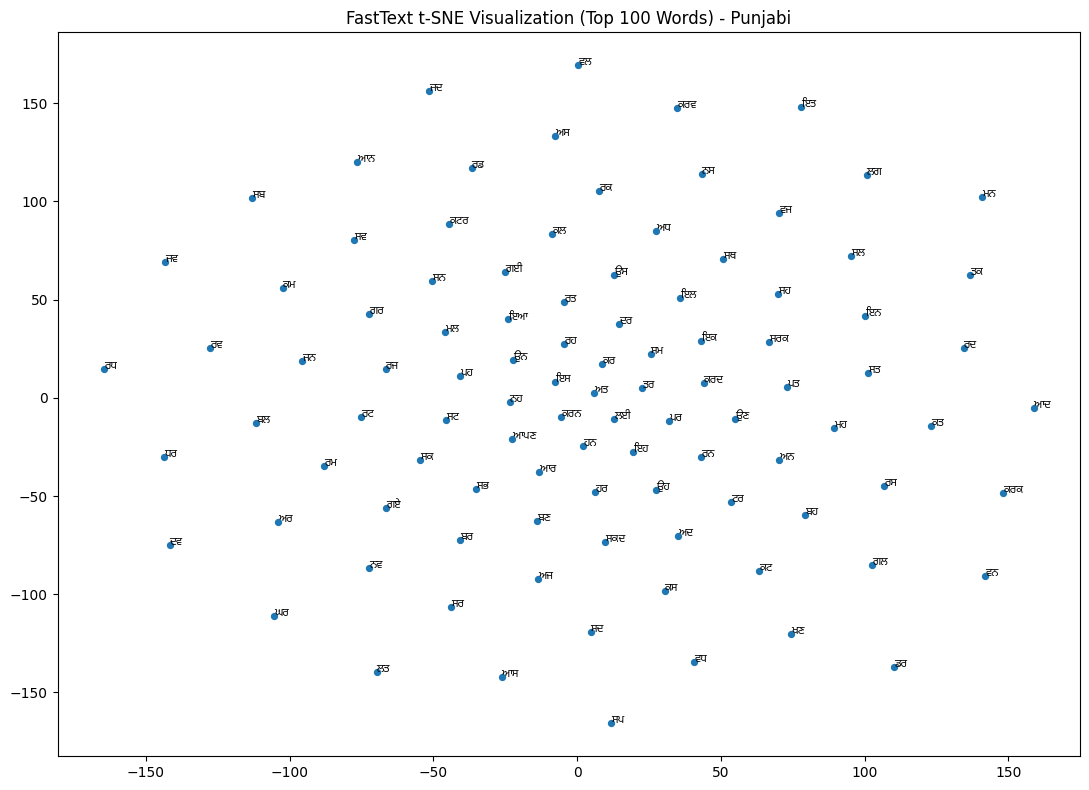

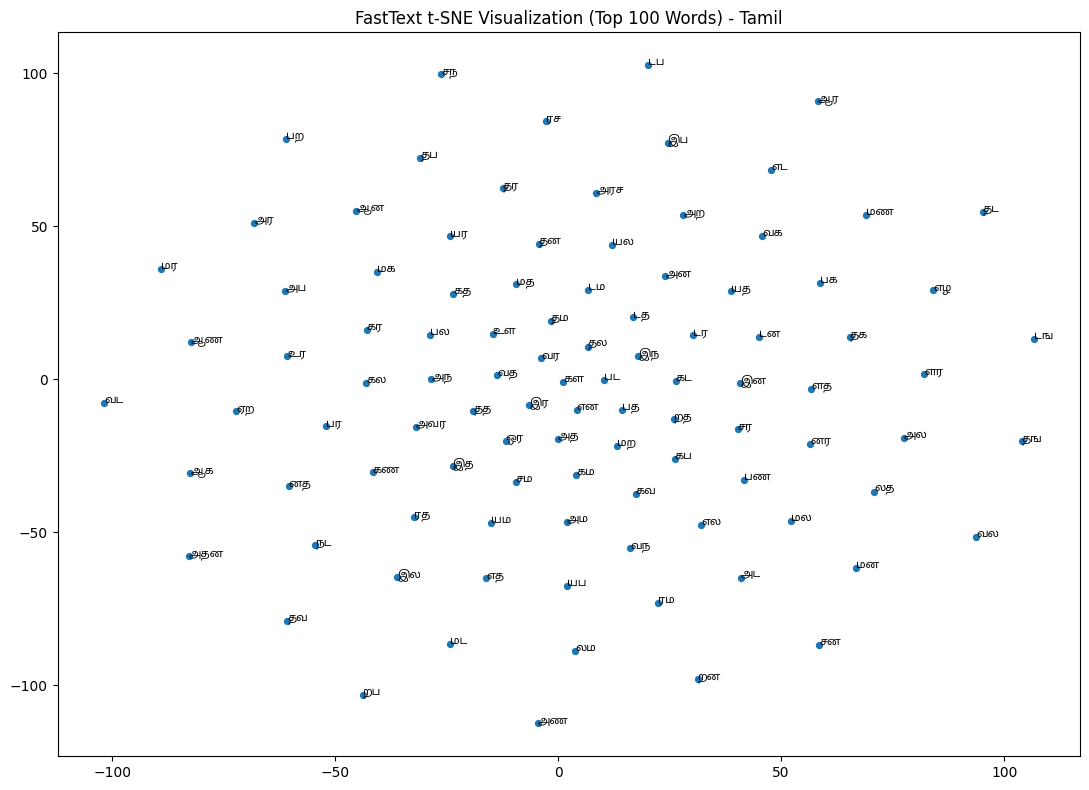

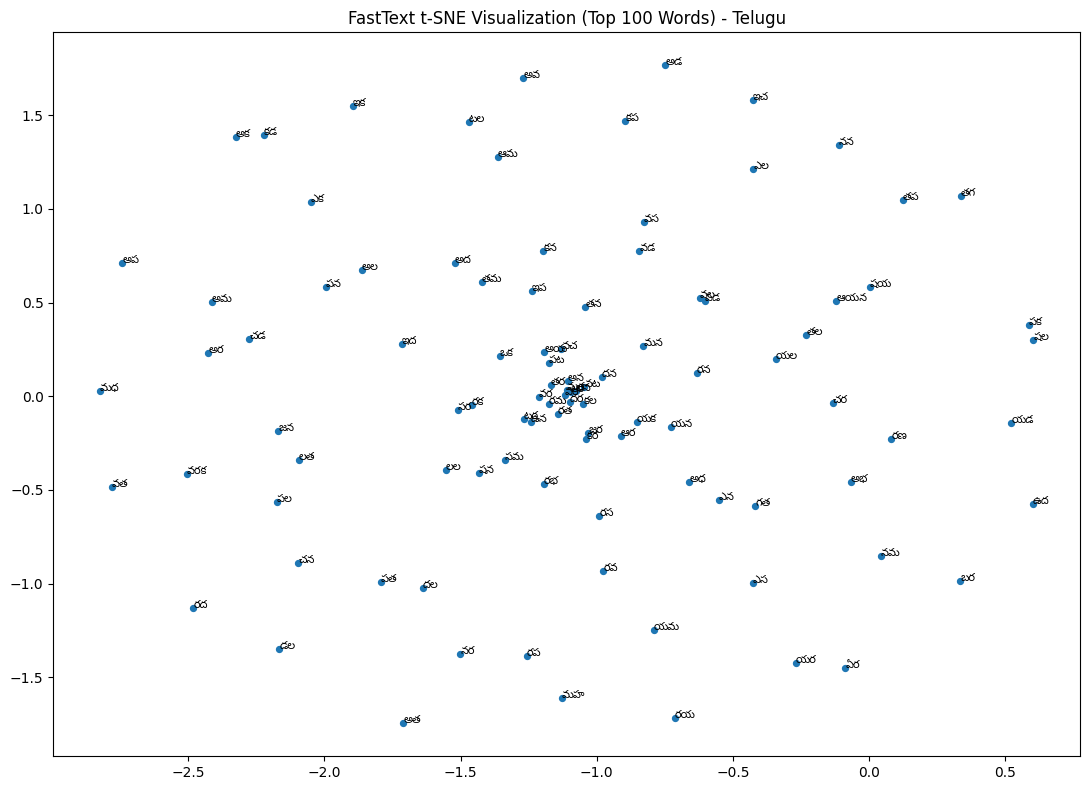

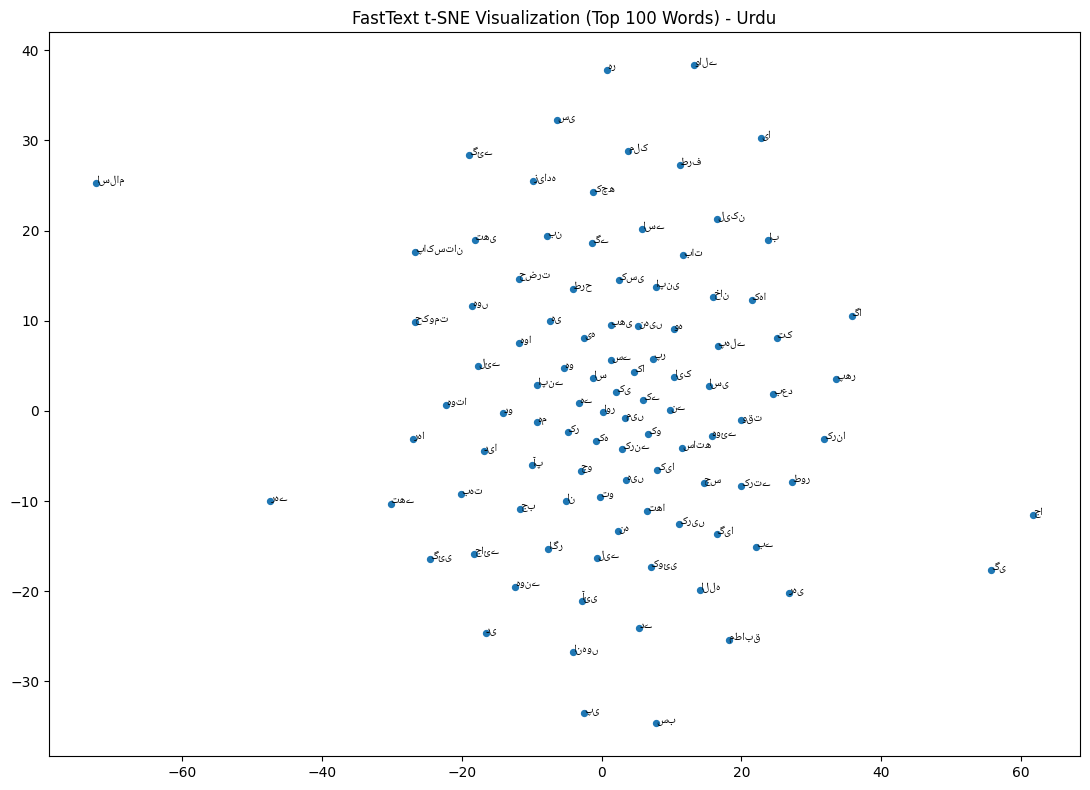

,Language,word1,word2,human_score,model_similarity,prediction_type
0,Gujarati,સમસ્યા,પડકાર,9.000,0.112868,Correctly ranked
1,Gujarati,ટેલિફોન,સંચાર,7.000,0.000000,Correctly ranked
2,Gujarati,પૈસા,રોકડ,7.000,0.000000,Correctly ranked
3,Gujarati,પ્રવાસ,ગાડી,7.000,0.000000,Correctly ranked
4,Gujarati,પૈસા,સંપત્તિ,7.000,0.000000,Correctly ranked
...,...,...,...,...,...,...
65,Urdu,پیسے,نقد,9.375,0.072489,Incorrectly ranked
66,Urdu,جنگ,فوجی,9.000,0.038728,Incorrectly ranked
67,Urdu,گلاس,جادوگر,2.000,0.303430,Incorrectly ranked
68,Urdu,ککڑی,آلو,3.000,0.332935,Incorrectly ranked


In [17]:
# %% [8] Visualizations & Qualitative Error Analysis
import matplotlib.font_manager as fm

# Load installed Noto Regular TTF fonts into Matplotlib immediately (no restart needed)
noto_fonts = {}
for font_path in Path("/usr/share/fonts").rglob("Noto*Regular.ttf"):
    fm.fontManager.addfont(str(font_path))
    noto_fonts[font_path.stem] = str(font_path)

LANG_FONT_STEMS = {
    "Gujarati": ("NotoSansGujarati-Regular",),
    "Hindi": ("NotoSansDevanagari-Regular",),
    "Marathi": ("NotoSansDevanagari-Regular",),
    "Punjabi": ("NotoSansGurmukhi-Regular",),
    "Tamil": ("NotoSansTamil-Regular",),
    "Telugu": ("NotoSansTelugu-Regular",),
    "Urdu": ("NotoNaskhArabic-Regular", "NotoSansArabic-Regular", "NotoNastaliqUrdu-Regular"),
}


def get_lang_font_path(lang: str) -> str | None:
    for stem in LANG_FONT_STEMS.get(lang, ()):
        if stem in noto_fonts:
            return noto_fonts[stem]
    return None


# 1. Spearman bar chart
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Language", y="Spearman", color="#4C72B0")
plt.title("FastText Word Similarity Evaluation Across Indian Languages")
plt.ylabel("Spearman Correlation")
plt.tight_layout()
plt.savefig(RESULT_DIR / "spearman_comparison.png", dpi=300)
plt.show()

# 2. t-SNE visualizations (100 most frequent words per language)
for lang, data in language_data.items():
    word_to_id = data["word_to_id"]
    selected_words = [w for w, _ in data["word_counts"].most_common() if w in word_to_id][:100]
    if len(selected_words) < 3:
        continue

    word_ids = [word_to_id[w] for w in selected_words]
    vectors = fasttext_models[lang]["vocab_vectors"][word_ids]

    reduced = TSNE(
        n_components=2,
        perplexity=min(30, len(selected_words) - 1),
        random_state=SEED,
        init="pca",
        learning_rate="auto",
    ).fit_transform(vectors)

    font_path = get_lang_font_path(lang)
    if font_path:
        family_name = fm.FontProperties(fname=font_path).get_name()
        font_prop = fm.FontProperties(family=[family_name, "DejaVu Sans"])
    else:
        font_prop = None

    plt.figure(figsize=(11, 8))
    plt.scatter(reduced[:, 0], reduced[:, 1], s=18)
    for i, w in enumerate(selected_words):
        plt.annotate(w, (reduced[i, 0], reduced[i, 1]), fontsize=8, fontproperties=font_prop)
    plt.title(f"FastText t-SNE Visualization (Top 100 Words) - {lang}")
    plt.tight_layout()
    plt.savefig(RESULT_DIR / f"tsne_{lang.lower()}.png", dpi=300)
    plt.show()

# 3. Qualitative error analysis (5 best & 5 worst ranked pairs per language)
analysis_examples = []
for lang, df in benchmark_data.items():
    temp = df.copy()
    temp["model_similarity"] = evaluation_predictions[lang]
    temp["human_rank"] = rankdata(temp["human_score"]) / len(temp)
    temp["model_rank"] = rankdata(temp["model_similarity"]) / len(temp)
    temp["rank_difference"] = (temp["human_rank"] - temp["model_rank"]).abs()
    temp["Language"] = lang

    analysis_examples.append(temp.nsmallest(5, "rank_difference").assign(prediction_type="Correctly ranked"))
    analysis_examples.append(temp.nlargest(5, "rank_difference").assign(prediction_type="Incorrectly ranked"))

analysis_df = pd.concat(analysis_examples, ignore_index=True)
results_df.to_csv(RESULT_DIR / "evaluation_results.csv", index=False)
coverage_df.to_csv(RESULT_DIR / "vocabulary_coverage.csv", index=False)
analysis_df.to_csv(RESULT_DIR / "word_pair_analysis.csv", index=False)
display(analysis_df[["Language", "word1", "word2", "human_score", "model_similarity", "prediction_type"]])

In [22]:
# %% [9] Print All Experimental Results & Statistics (No PDF)
print("=== Model & Training Configuration ===")
print(
    f"Model: FastText Skip-gram (SGNS) | Dim: {EMBEDDING_DIM} | Window: {WINDOW_SIZE} | "
    f"Min Count: {MIN_COUNT} | Neg Samples: {NEGATIVE_SAMPLES} | Batch Size: {BATCH_SIZE} | "
    f"LR: {LEARNING_RATE} | Epochs: {EPOCHS}"
)

print("\n=== Corpus & Vocabulary Stats ===")
corpus_stats = pd.DataFrame([
    {
        "Language": lang,
        "Sentences": len(data["encoded_sentences"]),
        "Vocab Size": len(data["word_to_id"]),
        "N-grams (3-6)": len(data["ngram_to_id"]),
    }
    for lang, data in sorted(language_data.items())
    if lang in benchmark_data
])
print(corpus_stats.to_string(index=False))

print("\n=== Word Similarity Results (Spearman) ===")
print(results_df.to_string(index=False))
print(f"\nMacro-average Spearman: {macro_spearman:.4f}")

print("\n=== Vocabulary Coverage & OOV Statistics ===")
print(coverage_df.to_string(index=False))

print("\n=== Top 5 Correctly Ranked Word Pairs ===")
best_ex = analysis_df[analysis_df["prediction_type"] == "Correctly ranked"].nsmallest(5, "rank_difference")
print(best_ex[["Language", "word1", "word2", "human_score", "model_similarity"]].to_string(index=False))

print("\n=== Top 5 Incorrectly Ranked Word Pairs ===")
worst_ex = analysis_df[analysis_df["prediction_type"] == "Incorrectly ranked"].nlargest(5, "rank_difference")
print(worst_ex[["Language", "word1", "word2", "human_score", "model_similarity"]].to_string(index=False))

=== Model & Training Configuration ===
Model: FastText Skip-gram (SGNS) | Dim: 300 | Window: 5 | Min Count: 2 | Neg Samples: 5 | Batch Size: 8192 | LR: 0.003 | Epochs: 150

=== Corpus & Vocabulary Stats ===
Language  Sentences  Vocab Size  N-grams (3-6)
Gujarati       4821        3128          13898
   Hindi       4888        2526          12451
 Marathi       4852        3135          14505
 Punjabi       4756        2567          11561
   Tamil       4802        2119          10737
  Telugu       4559        2290          10205
    Urdu       4842       13564          87398

=== Word Similarity Results (Spearman) ===
Language  Spearman  P-value  Total Pairs  OOV Token Occurrences  OOV Rate (%)
Gujarati -0.013178 0.867403          163                    312     95.705521
   Hindi -0.064492 0.324922          235                    445     94.680851
 Marathi  0.120665 0.222413          104                    193     92.788462
 Punjabi -0.130962 0.118982          143                    2

Evaluate on private dataset (please read README.md)

In [5]:
# %% [10] Standalone Model Loader & Arbitrary/OOV Word Embedding Inference
# Evaluators can run ONLY this cell in a fresh kernel (using saved models/*.pt)
import unicodedata
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn

MODEL_DIR = Path("models")
EMBEDDING_DIM = 300
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_MODEL_CACHE = {}


def get_character_ngrams(word: str, min_n: int = 3, max_n: int = 6) -> list[str]:
    wrapped = f"<{word}>"
    return list({
        wrapped[i : i + n]
        for n in range(min_n, max_n + 1)
        for i in range(len(wrapped) - n + 1)
    })


def load_model_checkpoint(language: str, model_dir: Path = MODEL_DIR) -> dict:
    lang_key = language.strip().lower()
    if lang_key in _MODEL_CACHE:
        return _MODEL_CACHE[lang_key]

    ckpt_path = model_dir / f"{lang_key}_fasttext.pt"
    if not ckpt_path.exists():
        raise FileNotFoundError(f"Saved model checkpoint not found: {ckpt_path}")

    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    ngram_to_id = ckpt["ngram_to_id"]
    emb = nn.EmbeddingBag(len(ngram_to_id), ckpt["embedding_dim"], mode="mean").to(DEVICE)
    emb.load_state_dict(ckpt["input_embeddings"])
    emb.eval()

    state = {
        "input": emb,
        "ngram_to_id": ngram_to_id,
        "word_to_id": ckpt["word_to_id"],
        "embedding_dim": ckpt["embedding_dim"],
    }
    _MODEL_CACHE[lang_key] = state
    return state


def generate_embedding(word: str, language: str, loaded_state: dict | None = None) -> np.ndarray:
    """Return a 300-dim embedding for any known or OOV word."""
    norm_word = unicodedata.normalize("NFC", str(word).strip().lower())

    if loaded_state is None:
        # Use in-memory model if training was just run; otherwise auto-load from models/*.pt
        if "fasttext_models" in globals() and language in fasttext_models and "language_data" in globals() and language in language_data:
            input_emb = fasttext_models[language]["input"]
            ngram_to_id = language_data[language]["ngram_to_id"]
            dim = EMBEDDING_DIM
        else:
            state = load_model_checkpoint(language)
            input_emb, ngram_to_id, dim = state["input"], state["ngram_to_id"], state["embedding_dim"]
    else:
        input_emb = loaded_state["input"]
        ngram_to_id = loaded_state["ngram_to_id"]
        dim = loaded_state.get("embedding_dim", EMBEDDING_DIM)

    ng_ids = [ngram_to_id[ng] for ng in get_character_ngrams(norm_word) if ng in ngram_to_id]
    if not ng_ids:
        return np.zeros(dim, dtype=np.float32)

    with torch.no_grad():
        ids_t = torch.tensor(ng_ids, dtype=torch.long, device=DEVICE)
        return input_emb.weight[ids_t].mean(dim=0).cpu().numpy().astype(np.float32)


def generate_pair_embeddings(word_pairs: list[tuple[str, str]], language: str) -> np.ndarray:
    """Return an (N, 2, 300) float32 array for a list of (word1, word2) pairs."""
    state = load_model_checkpoint(language)
    pairs = [
        np.stack([
            generate_embedding(w1, language, loaded_state=state),
            generate_embedding(w2, language, loaded_state=state),
        ])
        for w1, w2 in word_pairs
    ]
    return np.array(pairs, dtype=np.float32)

In [6]:
# Example: Private evaluation on arbitrary & OOV words without retraining
state = load_model_checkpoint("Gujarati")
vec = generate_embedding("નવોશબ્દ", "Gujarati", loaded_state=state)  # shape: (300,)

# Or evaluate a list of word pairs directly into shape (N, 2, 300):
pair_vecs = generate_pair_embeddings([("ભારત", "દેશ"), ("અજાણ્યોશબ્દ", "ભાષા")], "Gujarati")
print("Single vector shape:", vec.shape, "| Pair batch shape:", pair_vecs.shape)

Single vector shape: (300,) | Pair batch shape: (2, 2, 300)
